## Name : Prem Palkar
## Roll : B54
## PRN : 2324001050
## Project : Plant Disease Ditection

In [14]:
import tensorflow as tf

# Allow GPU memory to grow gradually instead of grabbing it all at once
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)
    print(f"GPU memory growth enabled for: {gpus[0].name}")
    print(f"GPU detected: {gpus[0]}")
else:
    print("No GPU found, running on CPU")

GPU memory growth enabled for: /physical_device:GPU:0
GPU detected: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

from PIL import Image   # Photo Image Library --> to load and read Images as store it as python object
import random

# ImageDataGenerator : A Keras utility that loads images from folders in batches, resizes them, normalizes them, and optionally applies data augmentation
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# To build CNN Model Architechture 
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout, BatchNormalization

# For compilation
from tensorflow.keras.optimizers import Adam

# Callbacks

from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

In [6]:
print("✅ TensorFlow:", tf.__version__)
print("✅ NumPy:", np.__version__)
print("✅ All libraries loaded successfully!")

✅ TensorFlow: 2.12.0
✅ NumPy: 1.23.5
✅ All libraries loaded successfully!


In [13]:
# Confirm GPU
print(tf.config.list_physical_devices('GPU'))

# Prevent memory overflow on 6GB VRAM
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 1 : Setup & Datset

In [19]:
# Load the dataset

# Using os - operating system library for accessing files and folders
import os

# Store the dataset path in a variable 
DATASET_PATH = "/mnt/d/Prem/Study/Sem 6/DL/DL LAB/plantvillage dataset/color"

# Storing list of classes names with sorting
classes = sorted(os.listdir(DATASET_PATH))

print(f"Total No of Classes : {len(classes)}")

print("First 10 Classes :")
for cls in classes[:10]:
    print(f"  → {cls}")

Total No of Classes : 38
First 10 Classes :
  → Apple___Apple_scab
  → Apple___Black_rot
  → Apple___Cedar_apple_rust
  → Apple___healthy
  → Blueberry___healthy
  → Cherry_(including_sour)___Powdery_mildew
  → Cherry_(including_sour)___healthy
  → Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  → Corn_(maize)___Common_rust_
  → Corn_(maize)___Northern_Leaf_Blight


## Step 2 : EDA & Data Preprocessing

In [20]:
# Counting images per class

image_counts = {}

for cls in classes:
    
    class_path = os.path.join(DATASET_PATH, cls)    # joins two paths --> DatasetPath/classname
    count = len(os.listdir(class_path))             # Counts the total image in each class
    image_counts[cls] = count                       # Stores the counts in dictionary
    
print(f"{'Class Name':<50} {'Image Count':>10}")
print("-" * 62)

for cls, count in image_counts.items():
    print(f"{cls:<50} {count:>10}")
print("-"*62)
print(f"{'Total Images':<50} {sum(image_counts.values()):>10}")

Class Name                                         Image Count
--------------------------------------------------------------
Apple___Apple_scab                                        630
Apple___Black_rot                                         621
Apple___Cedar_apple_rust                                  275
Apple___healthy                                          1645
Blueberry___healthy                                      1502
Cherry_(including_sour)___Powdery_mildew                 1052
Cherry_(including_sour)___healthy                         854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot        513
Corn_(maize)___Common_rust_                              1192
Corn_(maize)___Northern_Leaf_Blight                       985
Corn_(maize)___healthy                                   1162
Grape___Black_rot                                        1180
Grape___Esca_(Black_Measles)                             1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)               1076
Grape_

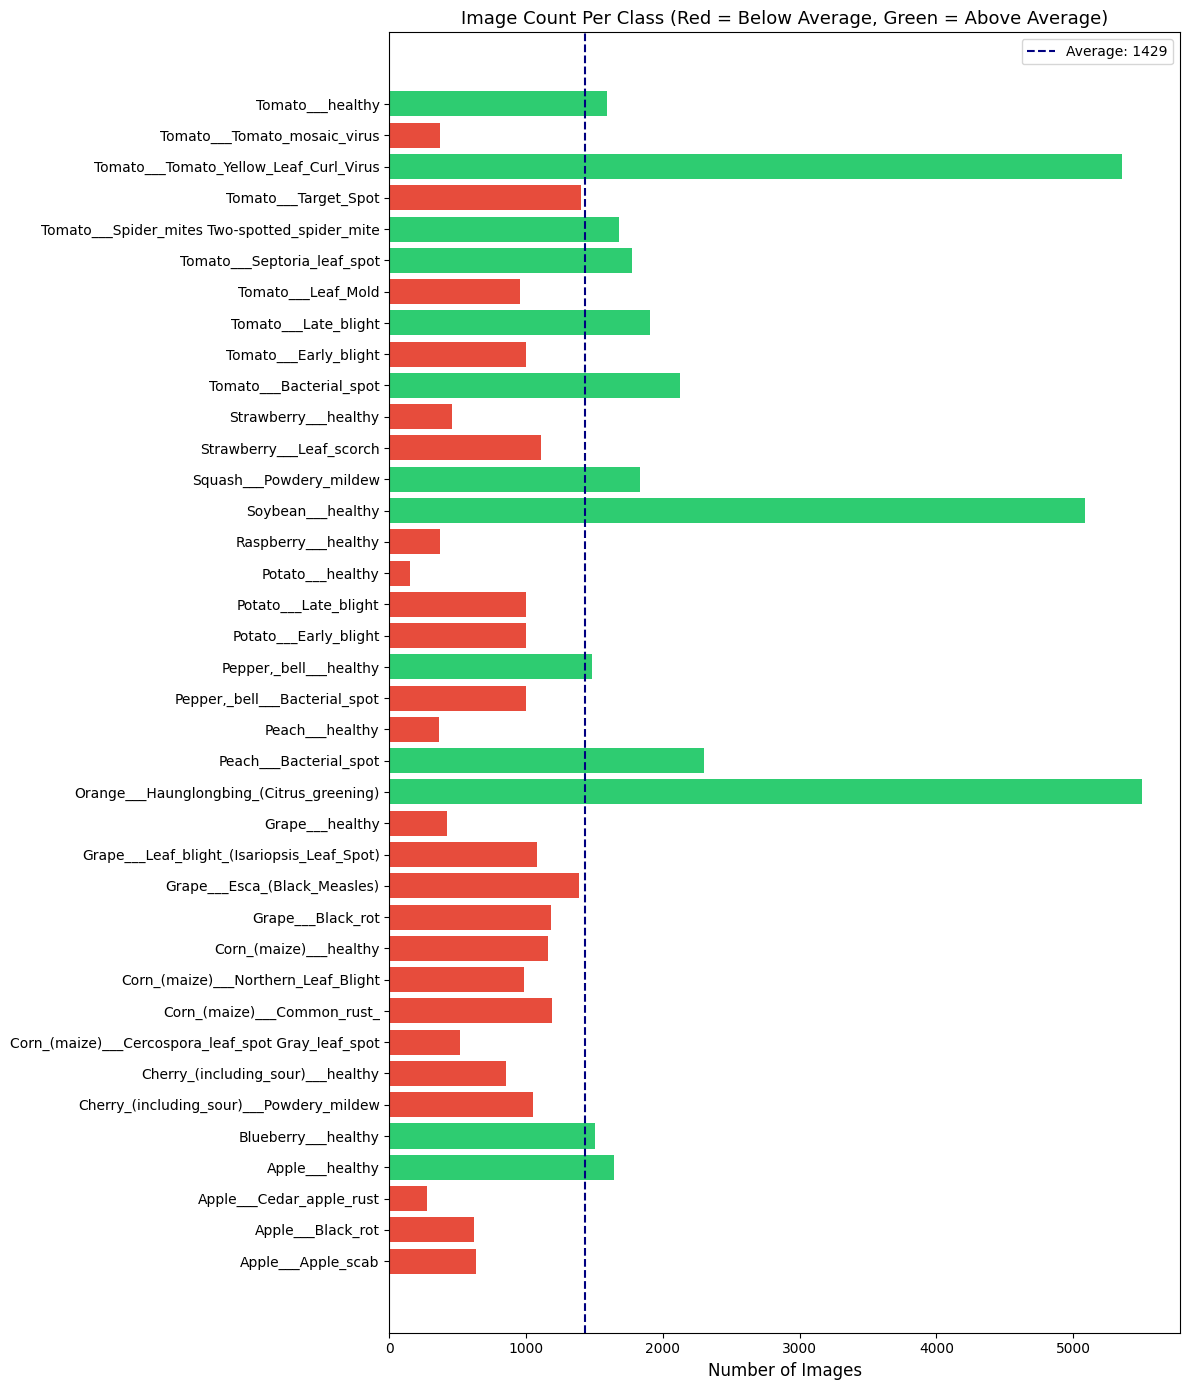

Average Images per class: 1429
MAX: 5507 | MIN: 152 | Ratio: 36.2x


In [14]:
# Visualize Classes

class_names = list(image_counts.keys())
counts = list(image_counts.values())
average = sum(counts)/len(counts)

plt.figure(figsize=(12,14))

colors = ['#e74c3c' if c < average else '#2ecc71' for c in counts]  # Different color indications
plt.barh(class_names, counts, color = colors)   # Horizontal Bar chart

# Draw Average line
plt.axvline(x=average, color='navy', linestyle ='--', linewidth=1.5, label = f"Average: {average:.0f}")

# Label and Titles
plt.xlabel("Number of Images", fontsize = 12)
plt.title('Image Count Per Class (Red = Below Average, Green = Above Average)', fontsize=13)
plt.legend()
plt.tight_layout()  #avoids ovalapping of names and data
plt.show()

print(f"Average Images per class: {average:.0f}")
print(f"MAX: {max(counts)} | MIN: {min(counts)} | Ratio: {max(counts)/min(counts):.1f}x")


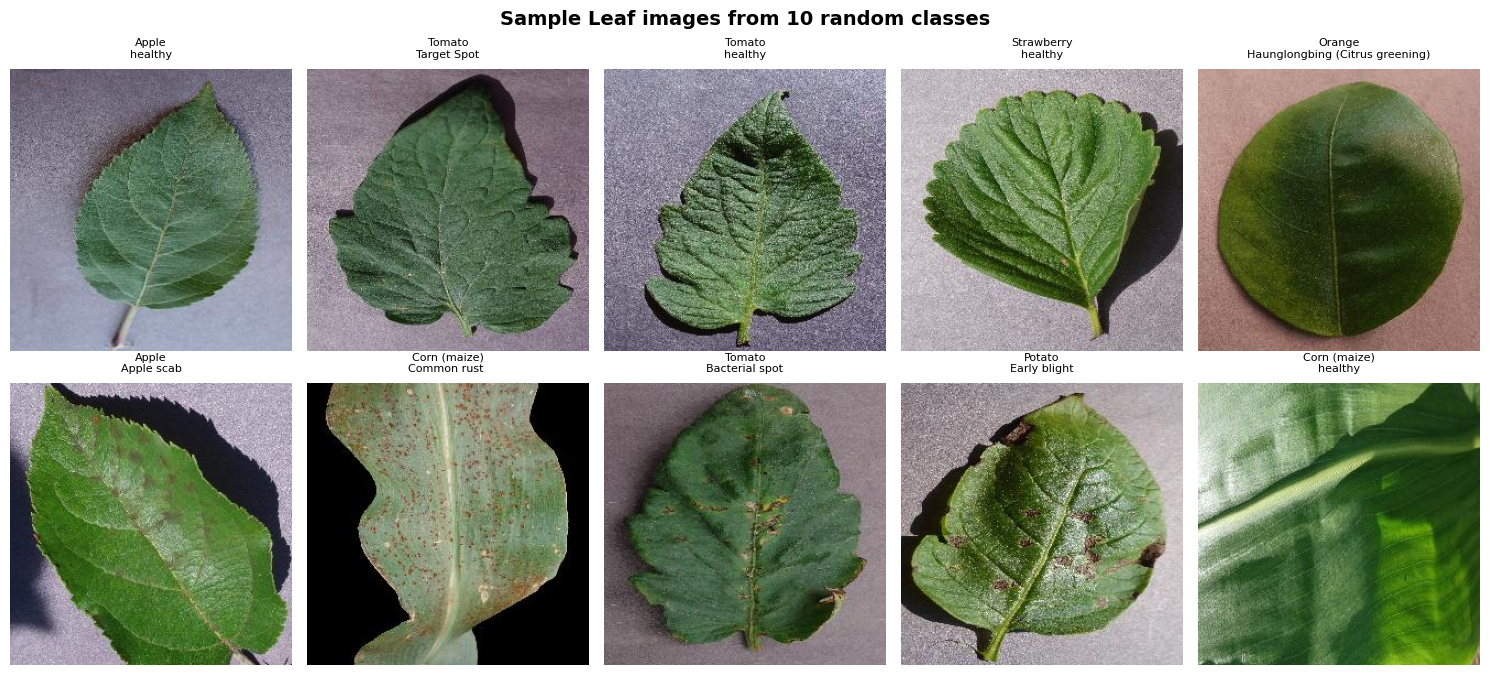

In [21]:
# Visualize Images

# Display 2 random images from 10 different classes
selected_classes = random.sample(classes, 10 ) # Pick 10 random classes

fig, axes = plt.subplots(2, 5, figsize=(15,7))   # 2 rows & 5 columns grid
axes = axes.flatten()

for i, cls in enumerate(selected_classes):
    class_path = os.path.join(DATASET_PATH, cls)
    
    image_name = random.choice(os.listdir(class_path))
    image_path = os.path.join(class_path, image_name)
    
    # Open and display the image
    img = Image.open(image_path)
    axes[i].imshow(img)
    axes[i].axis('off')
    
    display_name = cls.replace('___', '\n').replace('_', ' ')
    axes[i].set_title(display_name, fontsize=8, pad=8)
    
plt.suptitle('Sample Leaf images from 10 random classes', fontsize = 14, fontweight='bold')
plt.tight_layout()
plt.show()

In [22]:
#  Checking Image sizes

sizes = set()       # Stores unique sizes
sample_sizes = []   # Stores all sizes from samples for analysis

# Sample 500 random images accross all the classes
sample_count = 0

for cls in classes:
    class_path = os.path.join(DATASET_PATH, cls)
    images_in_class = os.listdir(class_path)
    
    # Sample 13 images per class so total gets approx 500
    sample_images = random.sample(images_in_class, min(13, len(images_in_class)))
     
    for img_name in sample_images:
        img_path = os.path.join(class_path, img_name)
        img = Image.open(img_path)
        sizes.add(img.size)                 # Add to unique set of data
        sample_sizes.append(img.size)       # add to full sample list
        sample_count += 1
        

print("Images Sampled : ", sample_count)
print("Total Unique Sizes : ", len(sizes))
print("\nAll unique sizes in dataset: ")
for s in sorted(sizes):
    print(f"  {s[0]} x {s[1]} pixels")

Images Sampled :  494
Total Unique Sizes :  1

All unique sizes in dataset: 
  256 x 256 pixels


In [33]:
# Loading & Preprocessing all Images

# Define Image size and batch Size
IMG_SIZE = (128, 128)       # Resize all images to 128x128
BATCH_SIZE = 32             # Load 32 images at a time

# Create the data generator
# Normalize the image by divinging every pixel by 256
datagen = ImageDataGenerator(
    rescale = 1./255,
    validation_split = 0.2  # 80% training and 20% validation
)

# Load Training Data
train_generator = datagen.flow_from_directory(  # Tells the generator: "go to this folder, read subfolders as class labels, load images from them."
    DATASET_PATH,
    target_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    class_mode = 'categorical',
    subset = 'training',
    shuffle = True,     # Shuffle order for unbias learning
    seed = 42           # just like random_state = 42
)

# Load Validation data
val_generator = datagen.flow_from_directory(
    DATASET_PATH,
    target_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    class_mode = 'categorical',
    subset = 'validation',
    shuffle = False,        # no need for shuffle for validation
    seed = 42
)

print(f"Training Images : {train_generator.samples}")
print(f"Validation Images : {val_generator.samples}")
print(f"Number of classes: {train_generator.num_classes}")
print(f"Batch Size : {BATCH_SIZE}")
print(f"Training Batches : {len(train_generator)}")
print(f"Validation Batches : {len(val_generator)}")

Found 43456 images belonging to 38 classes.
Found 10849 images belonging to 38 classes.
Training Images : 43456
Validation Images : 10849
Number of classes: 38
Batch Size : 32
Training Batches : 1358
Validation Batches : 340


## Step 3: Buidling Custom CNN

In [30]:
# Define Number of classes
NUM_CLASSES = 38

# Building CNN Model
model = Sequential([
    
    # 1 - 1st feature detector
    Conv2D(32, (3,3), activation='relu', padding='same', input_shape = (128,128,3)),     # input - 128x128 RGB
    BatchNormalization(),   # to normalize increased or decreaed values back to stable range
    MaxPooling2D(2,2),
    
    # 2 - Deeper feature detector
    Conv2D(64, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2,2),
    
    # 3 - More Deeper feacture detector
    Conv2D(128, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2,2),
    
    # 4 - Deepest feature detector
    Conv2D(256, (3,3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2,2),
    
    # Flatten and Classify
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.4),
    Dense(128, activation='relu'),
    Dropout(0.3),
    
    # 5 - Output Layer
    Dense(NUM_CLASSES, activation='softmax')    # 38 class probabilities
])

# Check for model summary
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_8 (Conv2D)           (None, 128, 128, 32)      896       
                                                                 
 batch_normalization_8 (Batc  (None, 128, 128, 32)     128       
 hNormalization)                                                 
                                                                 
 max_pooling2d_8 (MaxPooling  (None, 64, 64, 32)       0         
 2D)                                                             
                                                                 
 conv2d_9 (Conv2D)           (None, 64, 64, 64)        18496     
                                                                 
 batch_normalization_9 (Batc  (None, 64, 64, 64)       256       
 hNormalization)                                                 
                                                      

In [31]:
# Compiling the model

model.compile(
    optimizer = Adam(learning_rate=0.001),      # how to update the weights
    loss ='categorical_crossentropy',           # how to measure the error
    metrics = ['accuracy']                      # what to report
)

print("✅ Model compiled successfully!")
print(f"\nOptimizer : Adam (lr=0.001)")
print(f"Loss      : Categorical Crossentropy")
print(f"Metric    : Accuracy")

✅ Model compiled successfully!

Optimizer : Adam (lr=0.001)
Loss      : Categorical Crossentropy
Metric    : Accuracy


In [32]:
# (EXTRA) Callbacks : Stop training if the model stops improving in epochs

# 1. Save best model automatically
checkpoint = ModelCheckpoint(
    filepath='best_model.keras',    # where to save model
    monitor='val_accuracy',         # keep watch on model accuracy
    save_best_only=True,
    mode='max',                     # save with highest accuracy only
    verbose=1                       # Print message when it saves
)

# 2. Stop training if no improvements
early_stopping = EarlyStopping(
    monitor='val_accuracy',
    patience=5,                 # Wait for 5 epochs
    restore_best_weights=True,  # when stopped, reload best weights
    verbose=1
)

# 3. Reduce learning rate when stuck
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',     # watch validation loss
    factor=0.5,             # multiply lr by 0.5 (halve it)
    patience=3,             
    min_lr=1e-7,
    verbose=1
)

callback_list = [checkpoint, early_stopping, reduce_lr]

In [34]:
# Class Weights

total_samples = train_generator.samples
num_classes = train_generator.num_classes

class_indices = train_generator.class_indices  # {apple : 0, banana : 1, .....}

#  Count images per class in training set
train_class_counts = np.zeros(num_classes)

for cls_name, cls_idx in class_indices.items():
    cls_path = os.path.join(DATASET_PATH, cls_name)
    train_class_counts[cls_idx] = len(os.listdir(cls_path)) * 0.8   # as 20% part is for testing
    
# Calculate Weight for each class
class_weights = {}
for cls_idx in range(num_classes):
    class_weights[cls_idx] = total_samples / (num_classes * train_class_counts[cls_idx])    # low number of image classes get higher weightage
    
    
# Print Top 5 highest weightage class (have low number of images)
print("Top 5 classes needing most attention (Highest Weights):\n")
sorted_weights = sorted(class_weights.items(), key = lambda x : x[1], reverse=True)
idx_to_class = {v : k for k, v in class_indices.items()}

for cls_idx, weight in sorted_weights[:5]:
    print(f"  {idx_to_class[cls_idx]:<45} weight: {weight :.3f}")
    
print(f"\n✅ Callbacks and class weights ready!")
print(f"✅ Training will auto-save best model to 'best_model.keras'")

Top 5 classes needing most attention (Highest Weights):

  Potato___healthy                              weight: 9.404
  Apple___Cedar_apple_rust                      weight: 5.198
  Peach___healthy                               weight: 3.971
  Raspberry___healthy                           weight: 3.853
  Tomato___Tomato_mosaic_virus                  weight: 3.832

✅ Callbacks and class weights ready!
✅ Training will auto-save best model to 'best_model.keras'


In [35]:
# Train the model

history = model.fit(
    train_generator,
    epochs = 30,
    validation_data = val_generator,
    callbacks = callback_list,
    class_weight = class_weights
)

print("\n✅ Training Complete!")
print(f"   Total epochs trained: {len(history.history['accuracy'])}")
print(f"   Best val accuracy   : {max(history.history['val_accuracy']):.4f}")

Epoch 1/30


2026-05-20 16:03:56.722670: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype int32
	 [[{{node Placeholder/_0}}]]
2026-05-20 16:04:00.799088: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:424] Loaded cuDNN version 8600
2026-05-20 16:04:12.527817: I tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:637] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2026-05-20 16:04:12.927400: I tensorflow/compiler/xla/service/service.cc:169] XLA service 0x78f534aa2510 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-05-20 16:04:12.927551: I tensorflow/compiler/xla/service/service.cc:177]   StreamExecutor device (0): NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9
2026-05-20 16:

1358/1358 [==============================] - ETA: 0s - loss: 3.3275 - accuracy: 0.1410

2026-05-20 16:34:34.532842: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype int32
	 [[{{node Placeholder/_0}}]]



Epoch 1: val_accuracy improved from -inf to 0.19154, saving model to best_model.keras
1358/1358 [==============================] - 2252s 2s/step - loss: 3.3275 - accuracy: 0.1410 - val_loss: 2.9609 - val_accuracy: 0.1915 - lr: 0.0010
Epoch 2/30
1358/1358 [==============================] - ETA: 0s - loss: 2.6294 - accuracy: 0.2463
Epoch 2: val_accuracy improved from 0.19154 to 0.38031, saving model to best_model.keras
1358/1358 [==============================] - 672s 495ms/step - loss: 2.6294 - accuracy: 0.2463 - val_loss: 2.1273 - val_accuracy: 0.3803 - lr: 0.0010
Epoch 3/30
1358/1358 [==============================] - ETA: 0s - loss: 2.1538 - accuracy: 0.3459
Epoch 3: val_accuracy improved from 0.38031 to 0.46096, saving model to best_model.keras
1358/1358 [==============================] - 668s 492ms/step - loss: 2.1538 - accuracy: 0.3459 - val_loss: 1.7908 - val_accuracy: 0.4610 - lr: 0.0010
Epoch 4/30
1358/1358 [==============================] - ETA: 0s - loss: 1.7485 - accuracy: 

In [ ]:
def plot_training_history(history, model_name):
    """
    Plots accuracy and loss curves for both training and validation.
    Takes the history object returned by model.fit() and the model name.
    """
    
    # Extract values from history dictionary
    train_acc = history.history['accuracy']
    val_acc   = history.history['val_accuracy']
    train_loss = history.history['loss']
    val_loss   = history.history['val_loss']
    epochs     = range(1, len(train_acc) + 1)  # [1, 2, 3, ..., 30]
    
    # Create figure with 2 side-by-side plots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # ── LEFT PLOT: Accuracy ──────────────────────────────────
    axes[0].plot(epochs, train_acc, label='Train Accuracy',
                 color='#2ecc71', linewidth=2)
    axes[0].plot(epochs, val_acc,   label='Val Accuracy',
                 color='#e74c3c', linewidth=2)
    axes[0].set_title(f'{model_name} — Accuracy', fontsize=13)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Mark the best validation accuracy point
    best_epoch = val_acc.index(max(val_acc)) + 1
    best_acc   = max(val_acc)
    axes[0].annotate(f'Best: {best_acc:.4f}\n(Epoch {best_epoch})',
                     xy=(best_epoch, best_acc),
                     xytext=(best_epoch + 1, best_acc - 0.05),
                     arrowprops=dict(arrowstyle='->', color='black'),
                     fontsize=9)
    
    # ── RIGHT PLOT: Loss ─────────────────────────────────────
    axes[1].plot(epochs, train_loss, label='Train Loss',
                 color='#2ecc71', linewidth=2)
    axes[1].plot(epochs, val_loss,   label='Val Loss',
                 color='#e74c3c', linewidth=2)
    axes[1].set_title(f'{model_name} — Loss', fontsize=13)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.suptitle(f'Training History — {model_name}',
                 fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'history_{model_name.replace(" ", "_")}.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    
    # Print summary
    print(f"\n{model_name} — Training Summary")
    print(f"  Total epochs     : {len(train_acc)}")
    print(f"  Best val accuracy: {best_acc:.4f} at epoch {best_epoch}")
    print(f"  Final train acc  : {train_acc[-1]:.4f}")
    print(f"  Final val acc    : {val_acc[-1]:.4f}")
    gap = train_acc[-1] - val_acc[-1]
    print(f"  Overfitting gap  : {gap:.4f} ", end="")
    print("(healthy)" if gap < 0.05 else "(slight overfit)" if gap < 0.1 else "(overfit!)")

# Call the function with our CNN results
plot_training_history(history, 'Custom CNN')

: 